<a href="https://colab.research.google.com/github/ArduinoPLUS/aicar/blob/main/ConvolutionNeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Convolution Neural Network
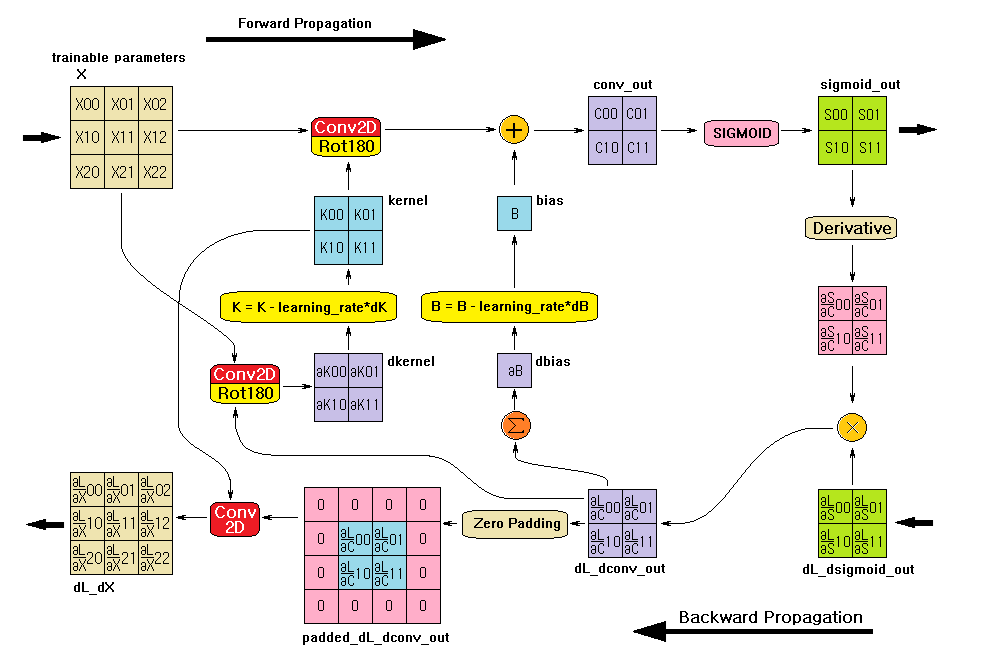

In [1]:
# Deep Neural Network and Convolution Neural Network - ConvolutionNewralNetwork.ipynb - 0
#
#
#
#
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

np.random.seed(12)       # Set a random seed for reproducibility

def sigmoid(x):                                  # Sigmoid 함수
  return 1 / (1 + np.exp(-x))
#-------------------------------------------------------------------------------
# Deep Neural Network Class
# 입력 Layer, 히든 Layer 1, 히든 Layer 2, 출력 Layer

class DNN:                                       # Deep Neural Network
  def __init__(self, input_size, hidden_size1, hidden_size2, output_size):
    self.input_size = input_size
    self.hidden_size1 = hidden_size1
    self.hidden_size2 = hidden_size2
    self.output_size = output_size
    # 가중치 W, 바이어스 B 초기화
    self.W3 = np.random.randn(input_size, hidden_size1)
    self.B3 = np.random.randn(1, hidden_size1)
    self.W2 = np.random.randn(hidden_size1, hidden_size2)
    self.B2 = np.random.randn(1, hidden_size2)
    self.W1 = np.random.randn(hidden_size2, output_size)
    self.B1 = np.random.randn(1, output_size)
    # Store intermediate values for backward pass
    self.S3 = None
    self.Y3 = None
    self.S2 = None
    self.Y2 = None
    self.S1 = None
    self.Y1 = None

  def forward(self, X):                          # 순전파 계산
    self.S3 = np.dot(X, self.W3) + self.B3
    self.Y3 = sigmoid(self.S3)
    self.S2 = np.dot(self.Y3, self.W2) + self.B2
    self.Y2 = sigmoid(self.S2)
    self.S1 = np.dot(self.Y2, self.W1) + self.B1
    self.Y1 = sigmoid(self.S1)
    return self.Y1

  def backward(self, X, D, learning_rate):       # 역전파 계산
    dL1 = (self.Y1 - D) * self.Y1 * (1 - self.Y1)
    dW1 = np.dot(self.Y2.T, dL1)
    dB1 = np.sum(dL1, axis=0, keepdims=True)
    dL2 = np.dot(dL1, self.W1.T) * self.Y2 * (1 - self.Y2)
    dW2 = np.dot(self.Y3.T, dL2)
    dB2 = np.sum(dL2, axis=0, keepdims=True)
    dL3 = np.dot(dL2, self.W2.T) * self.Y3 * (1 - self.Y3)
    dW3 = np.dot(X.T, dL3)
    dB3 = np.sum(dL3, axis=0, keepdims=True)

    # Calculate the gradient with respect to the input of the DNN (X)
    dL_dX = np.dot(dL3, self.W3.T)

    # 가중치 및 편향 업데이트
    self.W1 -= learning_rate * dW1
    self.B1 -= learning_rate * dB1
    self.W2 -= learning_rate * dW2
    self.B2 -= learning_rate * dB2
    self.W3 -= learning_rate * dW3
    self.B3 -= learning_rate * dB3

    # Return the gradient with respect to the input of the DNN
    return dL_dX
#-------------------------------------------------------------------------------
class CNN:                                          # Convolution Neural Network
  def __init__(self, kernel_size=(2, 2)):
    # Single CNN layer with configurable kernel size
    self.kernel_size = kernel_size
    self.kernel = np.random.randn(kernel_size[0], kernel_size[1]) # K kernel
    self.bias = np.random.randn()                                 # B bias
    # Store intermediate values for backward pass
    self.conv_out = None                  # C 컨볼루션 출력
    self.sigmoid_out = None               # S 활성화 함수 출력
    self.X = None                         # Store input for backward pass
    # Temporary Variables for debug
    self.dL_dconv_out = None
    self.dL_dsigmoid_out = None
    self.dL_dkernel = None
    self.dL_dbias = None
    self.dS_dC = None
    self.padded_dL_dconv_out = None
    self.dL_dX = None

  def forward(self, X):                                            # CNN forward
    self.X = X  # Store input for backward pass
    self.conv_out = convolve2d(X, np.rot90(self.kernel, k=2),\
                                mode='valid') + self.bias          # C 교차 상관
    self.sigmoid_out = sigmoid(self.conv_out)                      # S sigmoid out

    return self.sigmoid_out

  def backward(self, dL_dsigmoid_out, learning_rate):              # CNN Backward
    self.dL_dsigmoid_out = dL_dsigmoid_out
    self.dS_dC = self.sigmoid_out * (1 - self.sigmoid_out)
    self.dL_dconv_out = self.dL_dsigmoid_out * self.dS_dC

    # Gradient with respect to kernel (use stored input)
    self.dkernel = convolve2d(self.X, np.rot90(self.dL_dconv_out, k=2), mode='valid')
    self.dbias = np.sum(self.dL_dconv_out)

    # Update weights and biases
    self.kernel -= learning_rate * self.dkernel
    self.bias -= learning_rate * self.dbias

    # Calculate the gradient with respect to the input of the CNN (X)
    # Padding size should be (kernel_size - 1) to get the correct output size
    pad_h = self.kernel_size[0] - 1
    pad_w = self.kernel_size[1] - 1

    self.padded_dL_dconv_out = np.pad(self.dL_dconv_out,
                                      pad_width=((pad_h, pad_h), (pad_w, pad_w)),
                                      mode='constant', constant_values=0)
    # Use full convolution with the kernel (not rotated) to get gradient w.r.t. input
    self.dL_dX = convolve2d(self.padded_dL_dconv_out, self.kernel, mode='valid')

    return self.dL_dX
#-------------------------------------------------------------------------------


# CNN (CNN + CNN + DNN)
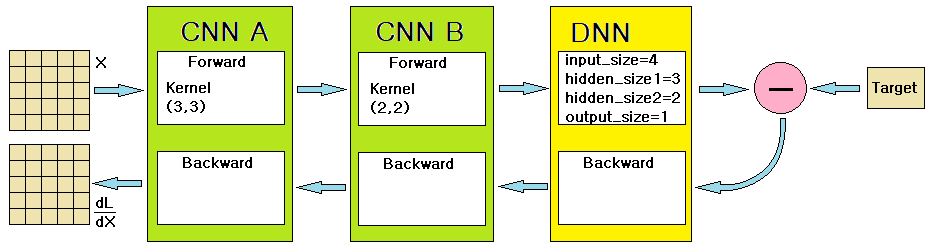

Starting training...

test_inputA(CNN A 테스트 입력): (5, 5) 
 [[0.11 0.12 0.13 0.14 0.15]
 [0.21 0.22 0.23 0.24 0.25]
 [0.31 0.32 0.33 0.34 0.35]
 [0.41 0.42 0.43 0.44 0.45]
 [0.51 0.52 0.53 0.54 0.55]]
cnn_outA(CNN A 순전파 출력 행렬): (3, 3) 
 [[0.88349562 0.87998134 0.87637589]
 [0.84408177 0.83959446 0.83500324]
 [0.79443649 0.78887775 0.78320972]]
cnn_outB(CNN B 순전파 출력 행렬): (2, 2) 
 [[0.75671689 0.75691174]
 [0.75886466 0.75910411]]
flattened_cnn_outB(리스트): (4,) 
 [0.75671689 0.75691174 0.75886466 0.75910411]
flattened_cnn_outB_reshaped(DNN 순전파/역전파 입력 행렬): (1, 4) 
 [[0.75671689 0.75691174 0.75886466 0.75910411]]
dL_dflattened_dnn: (1, 4) 
 [[-0.00065971 -0.00060764 -0.00029616  0.0010417 ]]
dL_dsigmoid_outB: (2, 2) 
 [[-0.00065971 -0.00060764]
 [-0.00029616  0.0010417 ]]
dL_dX_cnnB: (3, 3) 
 [[ 7.26051935e-05  9.45903536e-06 -5.28226272e-05]
 [-1.00704816e-04 -1.14435128e-04  2.25859570e-04]
 [-5.93947843e-05  2.74625540e-04 -2.31478816e-04]]
dL_dX_cnnA: (5, 5) 
 [[ 3.53478082e-06 -4.6200060

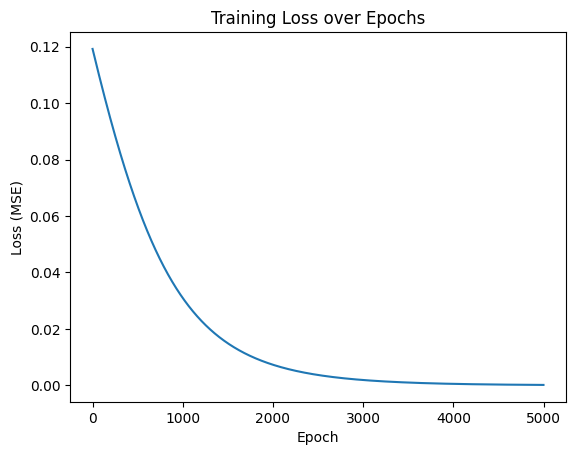

In [2]:
# CNN + CNN + DNN                                    - ConvolutionNewralNetwork.ipynb - 1
#
#
#
#
np.random.seed(12)       # Set a random seed for reproducibility

# Define learning rate and number of epochs
learning_rate = 0.01
epochs = 5000

# Instantiate the CNN and DNN classes
cnn_modelA = CNN(kernel_size=(3, 3))                  # kernel 크기를 (3,3)로 지정
cnn_modelB = CNN(kernel_size=(2, 2))                  # kernel 크기를 (2,2)로 지정
dnn_model = DNN(input_size=4, hidden_size1=3,hidden_size2=2, output_size=1)

# 학습 데이터(X)
test_inputA = np.array([[0.11, 0.12, 0.13, 0.14, 0.15],
                        [0.21, 0.22, 0.23, 0.24, 0.25],
                        [0.31, 0.32, 0.33, 0.34, 0.35],
                        [0.41, 0.42, 0.43, 0.44, 0.45],
                        [0.51, 0.52, 0.53, 0.54, 0.55]])

target_value = np.array([0.66])

# List to store loss values for plotting
loss_history = []

print("Starting training...\n")

# Training loop ----------------------------------------------------------------
for epoch in range(epochs):
  # Forward pass through CNN
  cnn_outA = cnn_modelA.forward(test_inputA)                      # CNN 순전파 A
  cnn_outB = cnn_modelB.forward(cnn_outA)                         # CNN 순전파 B

  # Flatten CNN output externally
  flattened_cnn_outB = cnn_outB.flatten()                         # List 형태로 변환
  flattened_cnn_outB_reshaped = flattened_cnn_outB.reshape(1, -1) # 1행 1열 형태로 변환

  # Forward pass through DNN
  dnn_output = dnn_model.forward(flattened_cnn_outB_reshaped)     # DNN 순전파

  # Calculate error (Mean Squared Error)
  error = target_value - dnn_output
  loss = np.mean(error**2)

  # Store the loss
  loss_history.append(loss)

  # Backward pass through DNN
  dL_dflattened_dnn = dnn_model.backward(flattened_cnn_outB_reshaped,\
                      target_value, learning_rate)                # DNN 역전파
  # Backward pass through CNN
  # Reshape gradient back to CNN output shape
  dL_dsigmoid_outB = dL_dflattened_dnn.reshape(cnn_outB.shape)
  dL_dX_cnnB = cnn_modelB.backward(dL_dsigmoid_outB, learning_rate) # CNN B 역전파
  dL_dX_cnnA = cnn_modelA.backward(dL_dX_cnnB, learning_rate)       # CNN A 역전파

  # Optionally print loss at intervals
  if (epoch + 1) % 100 == 0:
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.8f}")

  if epoch == 0:
    print('test_inputA(CNN A 테스트 입력):',test_inputA.shape,'\n',test_inputA)
    print('cnn_outA(CNN A 순전파 출력 행렬):',cnn_outA.shape,'\n',cnn_outA)
    print('cnn_outB(CNN B 순전파 출력 행렬):',cnn_outB.shape,'\n',cnn_outB)
    print('flattened_cnn_outB(리스트):',flattened_cnn_outB.shape,'\n',\
              flattened_cnn_outB)
    print('flattened_cnn_outB_reshaped(DNN 순전파/역전파 입력 행렬):',\
              flattened_cnn_outB_reshaped.shape,'\n',flattened_cnn_outB_reshaped)
    print('dL_dflattened_dnn:',dL_dflattened_dnn.shape,'\n', dL_dflattened_dnn)
    print('dL_dsigmoid_outB:',dL_dsigmoid_outB.shape,'\n', dL_dsigmoid_outB)
    print('dL_dX_cnnB:',dL_dX_cnnB.shape,'\n', dL_dX_cnnB)
    print('dL_dX_cnnA:',dL_dX_cnnA.shape,'\n', dL_dX_cnnA)

#-------------------------------------------------------------------------------
print("\nTraining finished.")
print("Final DNN output:", dnn_output)
print("Target value:", target_value)
print("Final Error:", np.mean(np.abs(error)))

# Plot the loss history
plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training Loss over Epochs')
plt.show()
#===============================================================================

# Stride
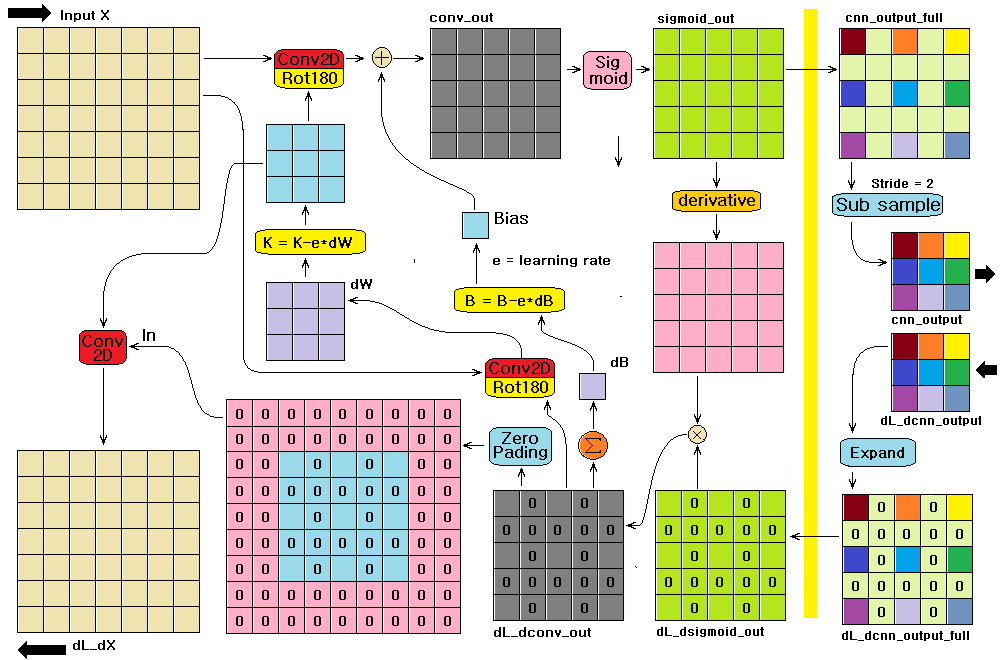

cnn_output_full (5, 5) 
 [[0.88349562 0.87998134 0.87637589 0.8726778  0.86888563]
 [0.84408177 0.83959446 0.83500324 0.83030717 0.82550537]
 [0.79443649 0.78887775 0.78320972 0.77743244 0.77154612]
 [0.73396594 0.72733323 0.7205981  0.71376208 0.70682686]
 [0.66324718 0.65567846 0.6480299  0.64030465 0.63250599]]
cnn_output (3, 3) 
 [[0.88349562 0.87637589 0.86888563]
 [0.79443649 0.78320972 0.77154612]
 [0.66324718 0.6480299  0.63250599]]
dnn_input_size 9
dnn_hidden_size1 9
dnn_hidden_size2 5
dnn_output_size 1

=== Training Start ===
X: (7, 7) 
 [[0.11 0.12 0.13 0.14 0.15 0.16 0.17]
 [0.21 0.22 0.23 0.24 0.25 0.26 0.27]
 [0.31 0.32 0.33 0.34 0.35 0.36 0.37]
 [0.41 0.42 0.43 0.44 0.45 0.46 0.47]
 [0.51 0.52 0.53 0.54 0.55 0.56 0.57]
 [0.61 0.62 0.63 0.64 0.65 0.66 0.67]
 [0.71 0.72 0.73 0.74 0.75 0.76 0.77]]
cnn_output_full: (5, 5) 
 [[0.88349562 0.87998134 0.87637589 0.8726778  0.86888563]
 [0.84408177 0.83959446 0.83500324 0.83030717 0.82550537]
 [0.79443649 0.78887775 0.78320972 0.

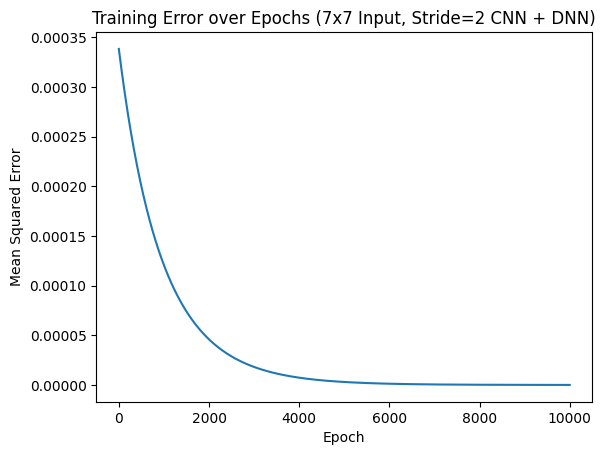

In [4]:
# Stride Example with 7x7 Input and Stride 2 Sampling - ConvolutionNewralNetwork.ipynb - 2
#
# CNN Layer + Stride + DNN Layer
#
#
np.random.seed(12)       # Set a random seed for reproducibility

# 입력 데이터 - 7x7 배열
X = np.array([[0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17],
              [0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27],
              [0.31, 0.32, 0.33, 0.34, 0.35, 0.36, 0.37],
              [0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47],
              [0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57],
              [0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67],
              [0.71, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77]])
# 목표값
Y = np.array([0.1234])

# Stride value
stride = 2

# Initialize CNN and get output shape to determine DNN input size
cnn = CNN(kernel_size=(3, 3))
cnn_output_full = cnn.forward(X)         # CNN 출력 (5,5)
cnn_output_full_shape = cnn_output_full.shape
cnn_output = cnn_output_full[::stride, ::stride]
cnn_output_shape = cnn_output.shape
dnn_input_size = cnn_output.flatten().shape[0] # (9,) 튜플 형식에서 첫번째(9)

dnn_hidden_size1 = dnn_input_size
dnn_hidden_size2 = 5
dnn_output_size = 1

print('cnn_output_full',cnn_output_full.shape,'\n',cnn_output_full)
print('cnn_output',cnn_output.shape,'\n',cnn_output)
print('dnn_input_size',dnn_input_size)
print('dnn_hidden_size1',dnn_hidden_size1)
print('dnn_hidden_size2',dnn_hidden_size2)
print('dnn_output_size',dnn_output_size)

# Initialize DNN
dnn = DNN(dnn_input_size, dnn_hidden_size1, dnn_hidden_size2, dnn_output_size)

# Training loop
errors = []
epochs = 10000
learning_rate = 0.01

print(f"\n=== Training Start ===")
#-------------------------------------------------------------------------------
for epoch in range(epochs):
  # Forward pass through CNN
  cnn_output_full = cnn.forward(X)
  # Apply stride sampling
  cnn_output = cnn_output_full[::stride, ::stride]
  flattened_cnn_output = cnn_output.flatten().reshape(1, -1)
  # Forward pass through DNN
  dnn_output = dnn.forward(flattened_cnn_output)
  # Calculate error (Mean Squared Error)
  error = np.mean((dnn_output - Y)**2)
  errors.append(error)
  # Backward pass through DNN
  dL_ddnn_input = dnn.backward(flattened_cnn_output, Y, learning_rate)
  # Reshape the gradient back to CNN output shape (3,3)
  dL_dcnn_output = dL_ddnn_input.reshape(cnn_output_shape)
  # Expand gradient from (3,3) back to (5,5)
  dL_dcnn_output_full = np.zeros(cnn_output_full_shape)
  dL_dcnn_output_full[::stride, ::stride] = dL_dcnn_output
  # Backward pass through CNN
  dL_dX = cnn.backward(dL_dcnn_output_full, learning_rate)

  if epoch == 0:
    print('X:',X.shape,'\n',X)
    print('cnn_output_full:',cnn_output_full.shape,'\n',cnn_output_full)
    print(f'cnn_output(stride={stride}):',cnn_output.shape,'\n',cnn_output)
    print('flattened_cnn_output:',flattened_cnn_output.shape,'\n',flattened_cnn_output)
    print('dnn_output:',dnn_output.shape,'\n',dnn_output)
    print('dL_ddnn_input:',dL_ddnn_input.shape,'\n',dL_ddnn_input)
    print('dL_dcnn_output:',dL_dcnn_output.shape,'\n',dL_dcnn_output)
    print(f'dL_dcnn_output_full(stride={stride}):',dL_dcnn_output_full.shape,'\n',\
          dL_dcnn_output_full)
    print('dL_dX:',dL_dX.shape,'\n',dL_dX)

  if (epoch + 1) % 500 == 0:
    print(f"Epoch {epoch+1}/{epochs}, Error: {error:.8f}")
#-------------------------------------------------------------------------------
print(f"\n=== Training Complete ===")
print(f"Final Error: {error:.8f}")
print(f"Final Output: {dnn_output[0][0]:.6f}")
print(f"Target: {Y[0]:.6f}")

# Plot training error
import matplotlib.pyplot as plt
plt.plot(errors)
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('Training Error over Epochs (7x7 Input, Stride=2 CNN + DNN)')
plt.show()
#===============================================================================

# MAX POOL
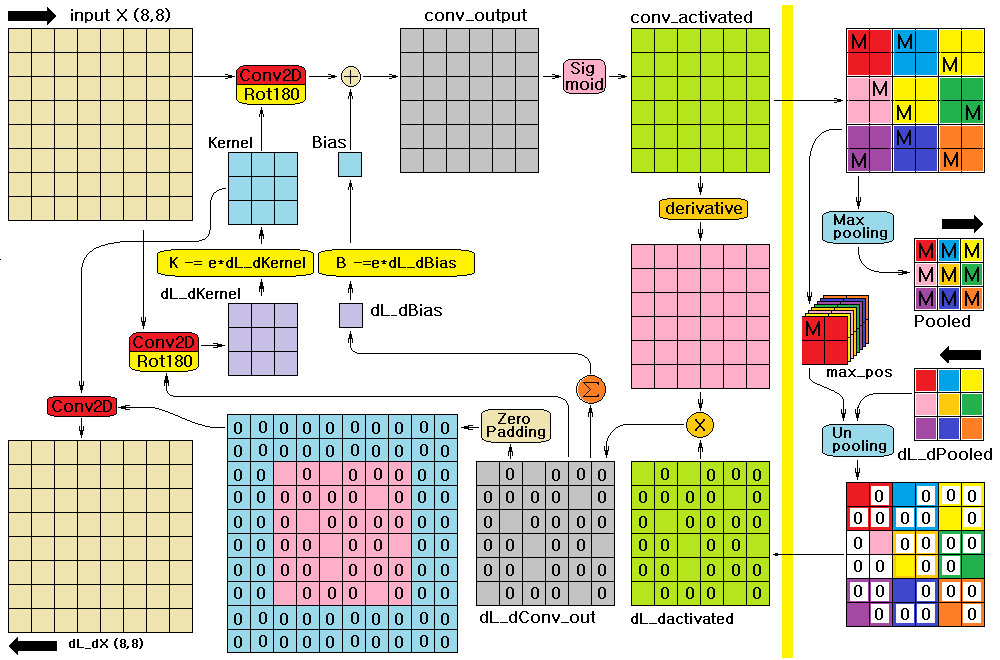

CNN + Max Pool + Deep Neural Network 학습 시작...

[i=0  j=0] self.pooled: (3, 3) 
 [[0.93914135 0.         0.        ]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]

[i=0  j=2] self.pooled: (3, 3) 
 [[0.93914135 0.91663611 0.        ]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]

[i=0  j=4] self.pooled: (3, 3) 
 [[0.93914135 0.91663611 0.98508079]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]

[i=2  j=0] self.pooled: (3, 3) 
 [[0.93914135 0.91663611 0.98508079]
 [0.96864976 0.         0.        ]
 [0.         0.         0.        ]]

[i=2  j=2] self.pooled: (3, 3) 
 [[0.93914135 0.91663611 0.98508079]
 [0.96864976 0.98640429 0.        ]
 [0.         0.         0.        ]]

[i=2  j=4] self.pooled: (3, 3) 
 [[0.93914135 0.91663611 0.98508079]
 [0.96864976 0.98640429 0.89897848]
 [0.         0.         0.        ]]

[i=4  j=0] self.pooled: (3, 3) 
 [[0.93914135 0.91663611 0.98508079]
 [0.96864976 0.98640429 0.

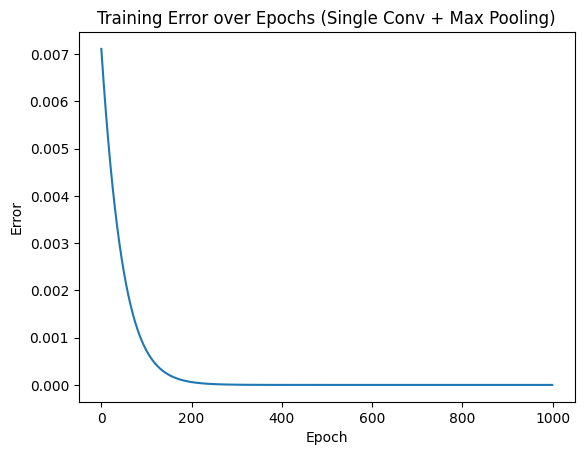

In [5]:
# Max Pool                                            - ConvolutionNewralNetwork.ipynb - 3
#
# CNN Layer + Max Pool Layer + DNN Layer
#
#
np.random.seed(12)       # Set a random seed for reproducibility

#-------------------------------------------------------------------------------
class MAXPOOL:
  def __init__(self, pool_size=2):
    self.pool_size = pool_size
    self.conv_activated = None
    self.pooled = None

  def forward(self, X, epoch):
    # Max pooling (2x2)
    self.conv_activated = X
    h, w = X.shape
    self.pooled = np.zeros((h//self.pool_size, w//self.pool_size))

    for i in range(0, h, self.pool_size):
      for j in range(0, w, self.pool_size):
        self.pooled[i//self.pool_size, j//self.pool_size] = \
          np.max(X[i:i+self.pool_size, j:j+self.pool_size])
        if epoch == 0:
          print(f"\n[i={i}  j={j}] self.pooled:", self.pooled.shape,"\n", self.pooled)

    if epoch == 0:
      print("\nself.pooled(Max Pooling Out):", self.pooled.shape,"\n", self.pooled)

    return self.pooled

  def backward(self, dL_dpooled, learning_rate, epoch):
    # Max pooling backward pass
    h, w = self.conv_activated.shape
    dL_dconv_activated = np.zeros((h, w))

    if epoch == 0:
      print("\nMAXPOOL Backward propagation")
      print("\ndL_dpooled(Gradient Loss from DNN):", dL_dpooled.shape,"\n", dL_dpooled)
      print("\ndL_dconv_activated:", dL_dconv_activated.shape,"\n", dL_dconv_activated)
      print(f"\nh = {h} w = {w}")

    for i in range(0, h, self.pool_size):
      for j in range(0, w, self.pool_size):
        pool_region = self.conv_activated[i:i+self.pool_size, j:j+self.pool_size]
        max_pos = np.unravel_index(np.argmax(pool_region), pool_region.shape)
        dL_dconv_activated[i + max_pos[0], j + max_pos[1]] = \
          dL_dpooled[i//self.pool_size, j//self.pool_size]

        if epoch == 0:
          print(f"\n[i={i} j={j}] pool_region:", pool_region.shape,"\n", pool_region)
          print(f"\n[i={i} j={j}] max_pos:", max_pos)
          print(f"\n[i={i} j={j}] dL_dconv_activated:", \
                dL_dconv_activated.shape,"\n", dL_dconv_activated)

    if epoch == 0:
      print("\ndL_dconv_activated:", dL_dconv_activated.shape,"\n", dL_dconv_activated)

    return dL_dconv_activated
#-------------------------------------------------------------------------------
# 입력 데이터 정의
test_input = np.round(np.random.rand(8, 8), 2)      # 8,8 소수점 2 자리 random
target = np.array([[0.55]])
epochs = 1000
learning_rate = 0.1

# CNN 초기화
cnn = CNN(kernel_size=(3, 3))

# MAXPOOL 초기화
maxpool = MAXPOOL(pool_size=2)

# DNN 초기화 (input_size는 max pooling 후 flatten된 크기: 3x3 = 9)
dnn = DNN(input_size=9, hidden_size1=6, hidden_size2=3, output_size=1)

# 학습 및 오차 저장
errors = []

print("CNN + Max Pool + Deep Neural Network 학습 시작...")
#-------------------------------------------------------------------------------
for epoch in range(epochs):

  # CNN Forward pass
  cnn_out = cnn.forward(test_input)
  # MAXPOOL Forward pass
  pooled_out = maxpool.forward(cnn_out, epoch)
  # Flatten pooled output for DNN
  flattened = pooled_out.flatten().reshape(1, -1)
  # DNN Forward pass
  out = dnn.forward(flattened)
  # DNN Backward pass
  dL_dFlattened = dnn.backward(flattened, target, learning_rate)
  # Reshape gradient back to pooled output shape
  dL_dpooled = dL_dFlattened.reshape(pooled_out.shape)
  # MAXPOOL Backward pass
  # Pass cnn_out to maxpool.backward as it needs the original input to the pooling layer
  dL_dconv_activated = maxpool.backward(dL_dpooled, learning_rate, epoch)
  # CNN Backward pass
  # Pass test_input to cnn.backward as it needs the original input to the CNN layer
  dL_dX = cnn.backward(dL_dconv_activated, learning_rate)

  if epoch == 0:
    print('\ncnn_out:',cnn_out.shape,'\n',cnn_out)
    print('\npooled_out:',pooled_out.shape,'\n',pooled_out)
    print('\nflattened.shape (Flattened for DNN):', flattened.shape,'\n', flattened)
    print('\ndL_dFlattened:', dL_dFlattened.shape,'\n', dL_dFlattened)
    print('\ndL_dpooled:', dL_dpooled.shape,'\n', dL_dpooled)
    print('\ndL_dconv_activated:', dL_dconv_activated.shape,'\n', dL_dconv_activated)
    print('\ndL_dX:', dL_dX.shape,'\n', dL_dX)

  # Calculate error
  error = 0.5 * (out - target) ** 2
  errors.append(error[0, 0])

  # Print progress
  if (epoch + 1) % 100 == 0:
    print(f"Epoch {epoch + 1}/{epochs}, Error: {error[0, 0]:.8f}, out: {out[0, 0]:.8f}")

print(f"\n학습 완료!")
print(f"최종 출력: {out[0, 0]:.8f}")
print(f"목표값: {target[0, 0]:.8f}")

# Error plot
plt.plot(errors)
plt.title('Training Error over Epochs (Single Conv + Max Pooling)')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.show()
#===============================================================================


# DROP OUT
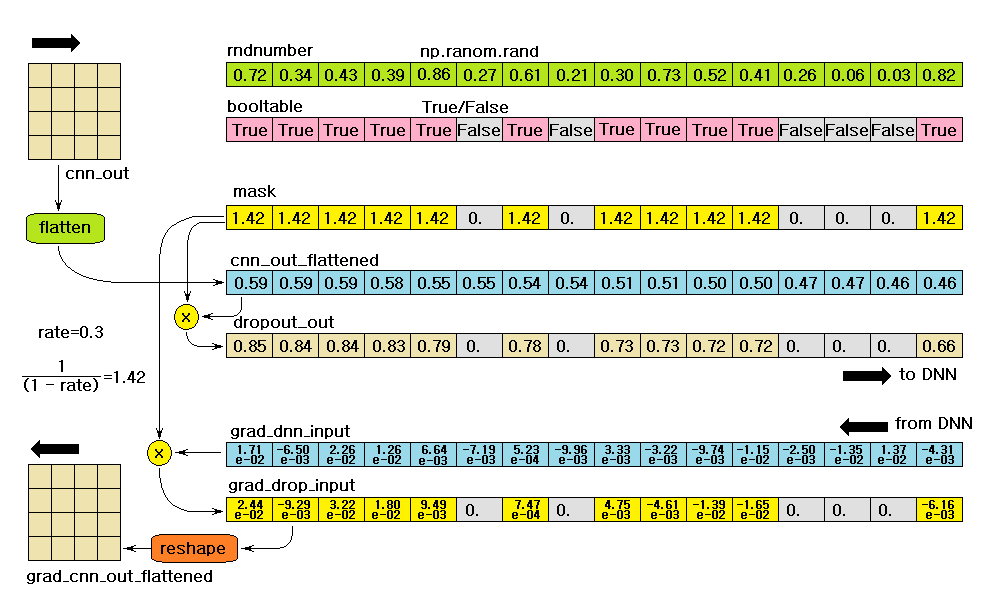


cnn_out: (4, 4) 
 [[0.59872385 0.59471295 0.59068936 0.5866536 ]
 [0.55810554 0.55399108 0.54986921 0.54574049]
 [0.51669464 0.51253138 0.50836639 0.50420023]
 [0.47505317 0.47089853 0.46674791 0.4626019 ]]

cnn_out_flattened: (1, 16) 
 [[0.59872385 0.59471295 0.59068936 0.5866536  0.55810554 0.55399108
  0.54986921 0.54574049 0.51669464 0.51253138 0.50836639 0.50420023
  0.47505317 0.47089853 0.46674791 0.4626019 ]]

dropout_out: (1, 16) 
 [[0.85531978 0.84958993 0.84384195 0.83807657 0.79729363 0.
  0.78552745 0.         0.7381352  0.73218769 0.72623769 0.72028604
  0.         0.         0.         0.66085985]]

rndnumber:
 [[0.7259149  0.34321611 0.43903784 0.39781527 0.86244835 0.27761431
  0.61139218 0.21913212 0.30641463 0.73440821 0.52385613 0.4189955
  0.2635038  0.06476168 0.03211953 0.82425167]]

booltable:
 [[ True  True  True  True  True False  True False  True  True  True  True
  False False False  True]]

mask: (1, 16) 
 [[1.42857143 1.42857143 1.42857143 1.42857143 1.42

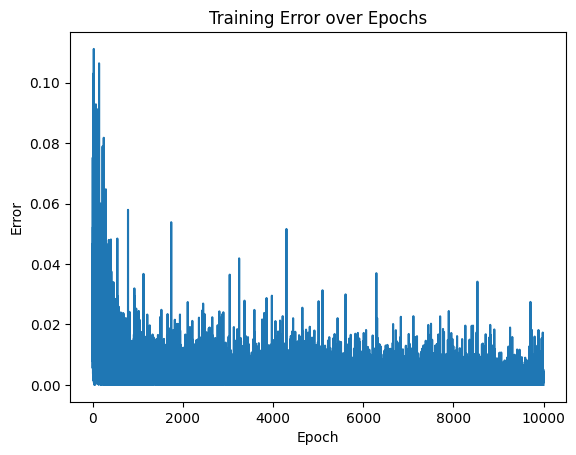

In [6]:
# Drop Out                                            - ConvolutionNewralNetwork.ipynb - 4
#
# CNN Layer + Drop Out Layer + Deep Neural Network
#
#
np.random.seed(12)       # Set a random seed for reproducibility

# Instantiate the CNN, Dropout, and DNN models
cnn = CNN(kernel_size=(2, 2))

# The output of the CNN with a 5x5 input and 2x2 kernel (stride 1, valid mode) is 4x4.
# This 4x4 output is flattened to 16 features for the DNN input.
dnn = DNN(input_size=16, hidden_size1=16, hidden_size2=10, output_size=1)

# Drop Out rate
rate = 0.3
mask = None

# Training parameters
epochs = 10000
learning_rate = 0.01
errors = []

# Assuming X is a single 5x5 input sample
X_input = np.array([[0.11, 0.12, 0.13, 0.14, 0.15],
                    [0.21, 0.22, 0.23, 0.24, 0.25],
                    [0.31, 0.32, 0.33, 0.34, 0.35],
                    [0.41, 0.42, 0.43, 0.44, 0.45],
                    [0.51, 0.52, 0.53, 0.54, 0.55]])

# Assuming Y is the target output for the single input sample
Y_target = np.array([[0.66]])
#-------------------------------------------------------------------------------
# Training loop
for epoch in range(epochs):
  # Forward pass through CNN
  cnn_out = cnn.forward(X_input) # CNN 순전파
  # Flatten the CNN output to match DNN input shape
  # Reshape to (1, num_features) since DNN expects batch_size as the first dimension
  cnn_out_flattened = cnn_out.flatten().reshape(1, -1)
  rndnumber = np.random.rand(*cnn_out_flattened.shape) # 16 개의 random 리스트 생성
  booltable = rndnumber > rate        # 0.3 보다 큰 값은 True, 작은 값은 False
  mask = booltable/ (1 - rate)        # True = 1 로 하고 계산 1/(1-0.3) = 1.42857143
  #mask = (np.random.rand(*cnn_output_flattened.shape) > rate) / (1 - rate)
  dropout_out = cnn_out_flattened * mask
  # Forward pass through DNN
  dnn_out = dnn.forward(dropout_out)
  # Calculate error (Mean Squared Error)
  error = np.mean((Y_target - dnn_out)**2)
  errors.append(error)

  # Backward pass through DNN
  # The DNN backward pass needs the output of the previous layer (dropout_output)
  # and the target output (Y_target).
  grad_dnn_input = dnn.backward(dropout_out, Y_target, learning_rate)

  # Backward pass through Dropout
  # The gradient from the DNN (grad_dnn_input) needs to be scaled by the mask
  grad_dropout_input = grad_dnn_input * mask

  # Reshape the gradient from Dropout output back to the shape of flattened CNN output
  # before unflattening for CNN backward pass
  grad_cnn_out_flattened = grad_dropout_input.reshape(cnn_out.shape)

  # Backward pass through CNN
  # The CNN backward pass needs the gradient from the next layer
  # (grad_cnn_output_flattened),
  # the learning rate, and the original input to the CNN (X_input).
  grad_cnn_input = cnn.backward(grad_cnn_out_flattened, learning_rate)

  if epoch == 0:
    print('\ncnn_out:',cnn_out.shape,'\n',cnn_out)
    print('\ncnn_out_flattened:',cnn_out_flattened.shape,'\n',cnn_out_flattened)
    print('\ndropout_out:',dropout_out.shape,'\n',dropout_out)
    print('\nrndnumber:\n',rndnumber)
    print('\nbooltable:\n',booltable)
    print('\nmask:',mask.shape,'\n',mask)
    print(f'\ngrad_dnn_input: {grad_dnn_input.shape}\n\
            {[f"{x:.2e}" for x in grad_dnn_input.flatten()]}')
    print(f'\ngrad_dropout_input: {grad_dropout_input.shape}\n\
            {[f"{x:.2e}" for x in grad_dropout_input.flatten()]}')
    #print('\ngrad_dropout_input:',grad_dropout_input.shape,'\n',grad_dropout_input)
    print('\ngrad_cnn_out_flattened:',grad_cnn_out_flattened.shape,'\n',\
            grad_cnn_out_flattened)
    print('\ngrad_cnn_input:',grad_cnn_input.shape,'\n',grad_cnn_input)

  if (epoch + 1) % 500 == 0:
    print(f'Epoch {epoch+1}/{epochs}, Error: {error:.8f}')
#-------------------------------------------------------------------------------
print("Training finished.")

import matplotlib.pyplot as plt
# Plot the error over epochs
plt.plot(errors)
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Training Error over Epochs')
plt.show()
#===============================================================================


# Multi Kernel
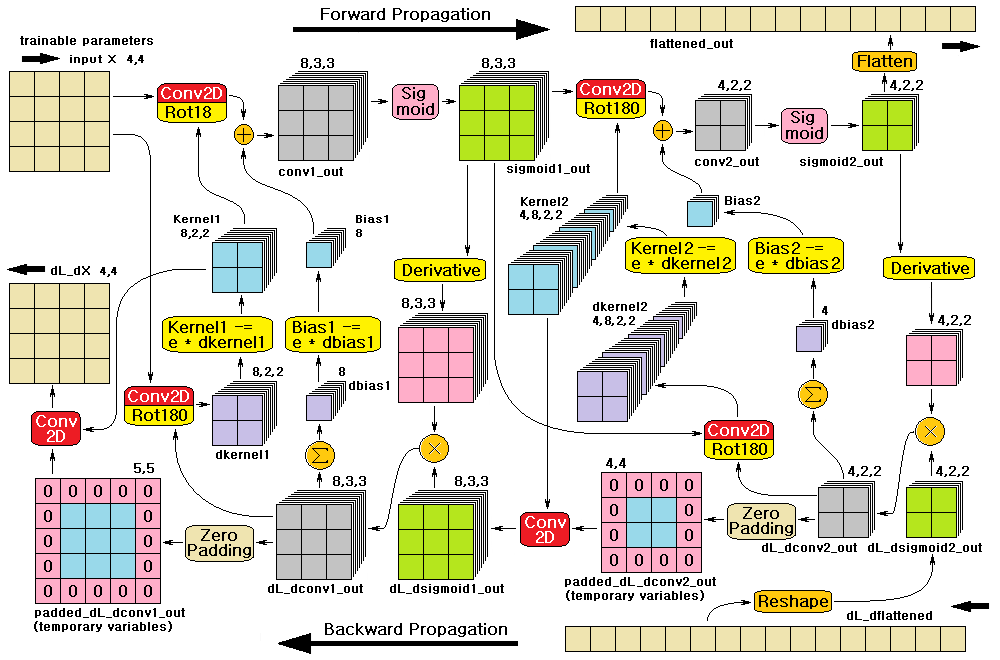

CNN class initialize ..........

self.kernel1:(8, 2, 2)
 [[[ 0.47298583 -0.68142588]
  [ 0.2424395  -1.70073563]]

 [[ 0.75314283 -1.53472134]
  [ 0.00512708 -0.12022767]]

 [[-0.80698188  2.87181939]
  [-0.59782292  0.47245699]]

 [[ 1.09595612 -1.2151688 ]
  [ 1.34235637 -0.12214979]]

 [[ 1.01251548 -0.91386915]
  [-1.02953021  1.20979645]]

 [[ 0.5018723   0.13884618]
  [ 0.64076111  0.52733267]]

 [[-1.15436024 -2.21333348]
  [-1.68175651 -1.78809425]]

 [[-2.21853495 -0.64743078]
  [-0.52840432 -0.03920917]]]

self.bias1:(8,)
 [ 0.21497595 -0.3843588  -0.25390408  0.07325207 -0.99720384 -0.71385629
  0.03541635 -0.67794537]

self.kernel2:(4, 8, 2, 2)
 [[[[-0.57188106 -0.10586232]
   [ 1.33583134  0.31866529]]

  [[-0.33759525 -0.58526828]
   [-0.11491994  2.24181779]]

  [[-3.14741652  0.53513589]
   [ 0.23249044  0.86761195]]

  [[-1.14821271  2.11434424]
   [ 1.00094276 -0.051415  ]]

  [[ 0.1597877  -0.71626359]
   [ 0.05052283 -0.14333741]]

  [[ 0.94357539  0.35764423]
   [-

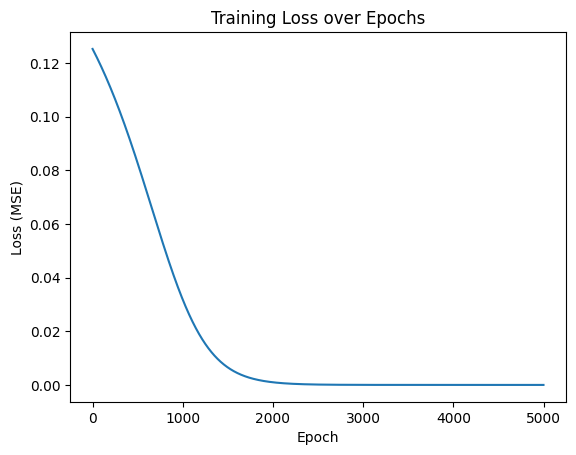

In [7]:
# Kernel Filter                               - ConvolutionNewralNetwork.ipynb - 5
# - Channels First Format (CHW)
#
#
#
#
import numpy as np
from scipy.signal import convolve2d
#
np.random.seed(12)                    # Set a random seed for reproducibility
#
def sigmoid(x):                        # Sigmoid 함수
  return 1 / (1 + np.exp(-x))
#
#-------------------------------------------------------------------------------
class DNN:
  def __init__(self, input_size, hidden_size1, hidden_size2, out_size):
    self.input_size = input_size
    self.hidden_size1 = hidden_size1
    self.hidden_size2 = hidden_size2
    self.out_size = out_size
#
    # 가중치 W, 바이어스 B 초기화
    self.W3 = np.random.randn(input_size, hidden_size1)
    self.B3 = np.random.randn(1, hidden_size1)
    self.W2 = np.random.randn(hidden_size1, hidden_size2)
    self.B2 = np.random.randn(1, hidden_size2)
    self.W1 = np.random.randn(hidden_size2, out_size)
    self.B1 = np.random.randn(1, out_size)
#
    # Store intermediate values for backward pass
    self.S3 = None
    self.Y3 = None
    self.S2 = None
    self.Y2 = None
    self.S1 = None
    self.Y1 = None
#
  def forward(self, X):                          # 순전파 계산
    self.S3 = np.dot(X, self.W3) + self.B3
    self.Y3 = sigmoid(self.S3)
    self.S2 = np.dot(self.Y3, self.W2) + self.B2
    self.Y2 = sigmoid(self.S2)
    self.S1 = np.dot(self.Y2, self.W1) + self.B1
    self.Y1 = sigmoid(self.S1)
    return self.Y1
#
  def backward(self, X, D, learning_rate):       # 역전파 계산
    dL1 = (self.Y1 - D) * self.Y1 * (1 - self.Y1)
    dW1 = np.dot(self.Y2.T, dL1)
    dB1 = np.sum(dL1, axis=0, keepdims=True)
    dL2 = np.dot(dL1, self.W1.T) * self.Y2 * (1 - self.Y2)
    dW2 = np.dot(self.Y3.T, dL2)
    dB2 = np.sum(dL2, axis=0, keepdims=True)
    dL3 = np.dot(dL2, self.W2.T) * self.Y3 * (1 - self.Y3)
    dW3 = np.dot(X.T, dL3)
    dB3 = np.sum(dL3, axis=0, keepdims=True)
#
    # Calculate the gradient with respect to the input of the DNN (X)
    # dL/dX = dL/dS3 * dS3/dX = dL3 * W3.T
    dL_dX = np.dot(dL3, self.W3.T)
#
    # 가중치 및 편향 업데이트
    self.W1 -= learning_rate * dW1
    self.B1 -= learning_rate * dB1
    self.W2 -= learning_rate * dW2
    self.B2 -= learning_rate * dB2
    self.W3 -= learning_rate * dW3
    self.B3 -= learning_rate * dB3
#
    # Return the gradient with respect to the input of the DNN
    return dL_dX
#-------------------------------------------------------------------------------
class CNN:
  def __init__(self):
#
    print('CNN class initialize ..........')
#
    # First CNN layer: input 4x4, kernel 2x2, stride 1, filter 8
    self.kernel1 = np.random.randn(8, 2, 2)       # 8 Kernels of size 2x2
    self.bias1 = np.random.randn(8)               # 8 Biases
    print(f'\nself.kernel1:{self.kernel1.shape}\n',self.kernel1)
    print(f'\nself.bias1:{self.bias1.shape}\n',self.bias1)
#
    # Second CNN layer: input from first layer out (8x3x3),
    # kernel 2x2, stride 1, filter 4
    # 4 Kernels of size 2x2, applied to 8 input channels
    self.kernel2 = np.random.randn(4, 8, 2, 2)
    self.bias2 = np.random.randn(4)               # 4 Biases
    print(f'\nself.kernel2:{self.kernel2.shape}\n',self.kernel2)
    print(f'\nself.bias2:{self.bias2.shape}\n',self.bias2)
#
    # Store intermediate values for backward pass (Channels, Height, Width)
    self.conv1_out = None           # 컨볼류션1 출력(Output shape: 8x3x3)
    self.sigmoid1_out = None        # 활성화 함수1 출력
    self.conv2_out = None           # 컨볼류션2 출력(Output shape: 4x2x2)
    self.sigmoid2_out = None        # 활성화 함수2 출력
#
  def forward(self, X, epoch):                             # CNN Forward
#
    if(epoch == 0): print('\nCNN Forward pass ..........')
    if(epoch == 0): print(f'\nX.shape:{X.shape}\n',X)
#
    # First CNN layer
    conv1_out_shape = (8, 3, 3)  # CHANNELS FIRST: (Channels, Height, Width)
    self.conv1_out = np.zeros(conv1_out_shape)    # 0 으로 초기화
    self.sigmoid1_out = np.zeros(conv1_out_shape) # 0 으로 초기화
#
    # Iterate through each filter in the first layer
    for i in range(self.kernel1.shape[0]):  # 8 Loop
      self.conv1_out[i, :, :] =\
      convolve2d(X, np.rot90(self.kernel1[i], k=2), mode='valid') + self.bias1[i] # 교차상관
      if(epoch == 0): print(f'\nconv1_out {i} {self.conv1_out.shape}\n',\
                            self.conv1_out)
#
    self.sigmoid1_out = sigmoid(self.conv1_out)
    if(epoch == 0): print(f'\nsigmoid1_out{self.sigmoid1_out.shape}\n',\
                          self.sigmoid1_out)
#
    # Second CNN layer
    conv2_out_shape = (4, 2, 2) # CHANNELS FIRST: (Channels, Height, Width)
    self.conv2_out = np.zeros(conv2_out_shape)
    self.sigmoid2_out = np.zeros(conv2_out_shape)
#
    # Iterate through each filter in the second layer
    for i in range(self.kernel2.shape[0]):         # 4 Loop
      temp_conv = np.zeros((2, 2))
      # Iterate through each input channel from the previous layer
      for j in range(self.kernel2.shape[1]):       # 8 Loop
        temp_conv += convolve2d(self.sigmoid1_out[j, :, :],\
        np.rot90(self.kernel2[i, j], k=2), mode='valid')                        # 교차 상관
#
      self.conv2_out[i, :, :] = temp_conv + self.bias2[i]
      if(epoch == 0): print(f'\nconv2_out {i} {self.conv2_out.shape}\n', self.conv2_out)
#
    self.sigmoid2_out = sigmoid(self.conv2_out)
    flattened_out = self.sigmoid2_out.flatten() # Flatten the out
#
    if(epoch == 0):
      print(f'\nsigmoid2_out:{self.sigmoid2_out.shape}\n', self.sigmoid2_out)
      print(f'\nflattened_out:{flattened_out.shape}\n', flattened_out)
#
    return flattened_out
#
  def backward(self, dL_dflattened, learning_rate, X, epoch):    # CNN Backward
#
    if epoch == 0: print('\nBackward pass ..........')
    if epoch == 0: print(f'\ndL_dflattened:{dL_dflattened.shape}\n',dL_dflattened)
#
    # Reshape the gradient from the flattened layer back to the shape of sigmoid2_out
    dL_dsigmoid2_out = dL_dflattened.reshape(self.sigmoid2_out.shape) # (4, 2, 2)
    if epoch == 0:
      print(f'\ndL_dsigmoid2_out:{dL_dsigmoid2_out.shape}\n',dL_dsigmoid2_out)
#
    # Backpropagate through the sigmoid activation of the second CNN layer
    dL_dconv2_out = dL_dsigmoid2_out * self.sigmoid2_out * (1 - self.sigmoid2_out)
    if epoch == 0: print(f'\ndL_dconv2_out:{dL_dconv2_out.shape}\n',dL_dconv2_out)
#
    # 4,8,2,2 Backpropagate through the second CNN layer
    dkernel2 = np.zeros(self.kernel2.shape)
    dbias2 = np.sum(dL_dconv2_out, axis=(1, 2)) # Sum over spatial dimensions
    if epoch == 0: print(f'\ndbias2:{dbias2.shape}\n',dbias2)
    dL_dsigmoid1_out = np.zeros(self.sigmoid1_out.shape)  # (8, 3, 3)
#
    # 4,8,2,2 Iterate through each filter in the second layer
    for i in range(self.kernel2.shape[0]): # 4 Loop
      padded_dL_dconv2_out = np.pad(dL_dconv2_out[i, :, :], pad_width=1,\
      mode='constant', constant_values=0) # 1 개의 임시 변수
#
      if epoch == 0: print(f'\npadded_dL_dconv2_out:{i}\n',padded_dL_dconv2_out)
#
      # 4,8,2,2 Iterate through each input channel from the previous layer
      for j in range(self.kernel2.shape[1]): # 8 Loop
        # i=4 j=8 (sigmoid1_out=8장) 따라서 dkernel2 = 4 x 8 = 32장
        dkernel2[i, j] = convolve2d(self.sigmoid1_out[j, :, :],\
                         np.rot90(dL_dconv2_out[i, :, :],k=2), mode='valid') # 교차 상관
        # j=8, dL_dsigmoid1_out 은 1장(i)씩 8개 kernel2 conv 하여 합산 후
        # 한장으로 만들고 8장(j)으로 저장
        dL_dsigmoid1_out[j, :, :] += \
          convolve2d(padded_dL_dconv2_out, self.kernel2[i, j], mode='valid') # Math. Conv
#
    # Backpropagate through the sigmoid activation of the first CNN layer
    dL_dconv1_out = dL_dsigmoid1_out * self.sigmoid1_out * (1 - self.sigmoid1_out)
    if epoch == 0: print(f'\ndL_dconv1_out:{dL_dconv1_out.shape}\n',dL_dconv1_out)
#
    # Backpropagate through the first CNN layer
    dkernel1 = np.zeros(self.kernel1.shape)
    dbias1 = np.sum(dL_dconv1_out, axis=(1, 2)) # sum over spatial dimensions
    dL_dX = np.zeros(X.shape) # Gradient with respect to the input of the CNN
#
    # 8,2,2 Iterate through each filter in the first layer
    for i in range(self.kernel1.shape[0]): # 8 Loop
      dkernel1[i]=convolve2d(X,np.rot90(dL_dconv1_out[i,:,:],k=2),mode='valid') # 교차 상관
#
      # Calculate the gradient with respect to the input of the CNN (X)
      # dL/dX = dL/dS1 * dS1/dX = dL_dconv1_out * kernel1.T
      # Need to pad dL_dconv1_out to match the input shape size after convolution
      padded_dL_dconv1_out = np.pad(dL_dconv1_out[i, :, :], pad_width=1,\
                             mode='constant', constant_values=0) # zero padding
#
      dL_dX += convolve2d(padded_dL_dconv1_out, self.kernel1[i], mode='valid') # Math. Conv
#
    self.kernel2 -= learning_rate * dkernel2    # Update weights and biases
    self.bias2 -= learning_rate * dbias2
    self.kernel1 -= learning_rate * dkernel1
    self.bias1 -= learning_rate * dbias1
#
    if epoch == 0:
      print(f'\npadded_dL_dconv1_out:{padded_dL_dconv1_out.shape}\n',\
            padded_dL_dconv1_out)
      print(f'\ndkernel1:{dkernel1.shape}\n',dkernel1)
      print(f'\ndbias1:{dbias1.shape}\n',dbias1)
      print(f'\ndkernel2:{dkernel2.shape}\n',dkernel2)
      print(f'\ndbias2:{dbias2.shape}\n',dbias2)
      print(f'\nself.kernel1:{self.kernel1.shape}\n',self.kernel1)
      print(f'\nself.bias1:{self.bias1.shape}\n',self.bias1)
      print(f'\nself.kernel2:{self.kernel2.shape}\n',self.kernel2)
      print(f'\nself.bias2:{self.bias2.shape}\n',self.bias2)
      print(f'\ndL_dX:{dL_dX.shape}\n',dL_dX)
#
    # dL_dX 는 입력 X 가 trained parameter 일 때 의미가 있다.
    # Return the gradient with respect to the input of the CNN
    return dL_dX
#
#===============================================================================
# Define learning rate and number of epochs
learning_rate = 0.01
epochs = 5000
#
# Instantiate the CNN and NeuralNetwork classes
cnn_model = CNN()
# The out of the second CNN layer is 4x2x2 (channels first),
# which flattens to a size of 4*2*2 = 16.
# The NeuralNetwork class takes input_size, hidden_size1, hidden_size2, out_size.
# We will set hidden_size1=8, hidden_size2=4, and out_size=1.
dnn_input_size = 4 * 2 * 2                                         # 16
dnn_hidden_size1 = 8
dnn_hidden_size2 = 4
dnn_out_size = 1
dnn_model = DNN(input_size=dnn_input_size, hidden_size1=dnn_hidden_size1, \
                hidden_size2=dnn_hidden_size2, out_size=dnn_out_size)
#
# 학습 데이터(X)
test_input = np.array([[0.11, 0.12, 0.13, 0.14],
                       [0.21, 0.22, 0.23, 0.24],
                       [0.31, 0.32, 0.33, 0.34],
                       [0.41, 0.42, 0.43, 0.44]])
#
target_value =np.array([0.55])    # sigmoid 를 사용하므로 반드시 0~1 범위의 수
#
loss_history = []                 # List to store loss values for plotting
#
# Training loop
print("\nStarting training...\n")
for epoch in range(epochs):
  # Forward pass through CNN
  flattened_cnn_out = cnn_model.forward(test_input, epoch)
  if epoch == 0:
    print(f'\nMain A flattened_cnn_out:{flattened_cnn_out.shape}\n', flattened_cnn_out)
#
  # Reshape flattened CNN out for DNN
  flattened_cnn_out_reshaped = flattened_cnn_out.reshape(1, -1)
  if epoch == 0:
    print(f'\nMain B flattened_cnn_out_reshaped:\
      {flattened_cnn_out_reshaped.shape}\n',flattened_cnn_out_reshaped)
#
  # Forward pass through NeuralNetwork
  dnn_out = dnn_model.forward(flattened_cnn_out_reshaped)
  if epoch == 0: print(f'\nMain C dnn_out:{dnn_out.shape}\n',dnn_out)
#
  # Calculate error (Mean Squared Error)
  error = target_value - dnn_out
  loss = np.mean(error**2)
#
  # Store the loss
  loss_history.append(loss)
#
  # Backward pass through NeuralNetwork
  # The backward method now returns the gradient with respect to its input
  dL_dflattened_cnn_out = dnn_model.backward(flattened_cnn_out_reshaped,\
                                             target_value, learning_rate)
#
  if epoch == 0:
    print('loss\n',loss)
    print('dL_dflattened_cnn_out\n',dL_dflattened_cnn_out.shape)
  # Optionally print loss at intervals
  if (epoch + 1) % 100 == 0:
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.8f}")
  # Backward pass through CNN
  # Pass the gradient from the flattened layer back to the CNN
  cnn_model.backward(dL_dflattened_cnn_out.flatten(), learning_rate, \
                     test_input, epoch)
#
print("\nTraining finished.")
print("Final DNN out:", dnn_out)
print("Target value:", target_value)
# Mean Absolute Error as a measure of final error
print("Final Error:", np.mean(np.abs(error)))
#
import matplotlib.pyplot as plt
# Plot the loss history
plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training Loss over Epochs')
plt.show()
#